# 06b Projected AMR-SI Change for Notebook 06 Pairs

Plot projected SI change for the same pairs retained in Notebook 06's `latest_count_shift_df`. The figure uses that dataframe's pair rows and Notebook 06 forecast values directly, so its points and filters stay aligned with Notebook 06. Orange points mark pairs also present in the cleaned GLASS list.

Run Notebook 06 first to refresh `outputs/figures/future_si_vs_current_si_quadrant.csv`; this notebook does not add or remove pairs.

In [29]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.si import build_si_analysis_paths

## Configuration

In [31]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

FIGURE_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT)
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NB06_PLOT_DATA_PATH = FIGURE_OUTPUT_DIR / "future_si_vs_current_si_quadrant.csv"

SAVE_FIGURE = True
FIGURE_STEM = FIGURE_OUTPUT_DIR / "nb06_projected_amr_si_change"

if not NB06_PLOT_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {NB06_PLOT_DATA_PATH}. Run Notebook 06 through the cell that saves latest_count_shift_df first."
    )

print(f"Notebook 06 filtered pairs: {NB06_PLOT_DATA_PATH}")
print("Using the Notebook 06 pair rows and SI changes without additional filtering.")

Notebook 06 filtered pairs: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/future_si_vs_current_si_quadrant.csv
Using the Notebook 06 pair rows and SI changes without additional filtering.


## Load Notebook 06 Filtered Pairs

In [32]:
latest_count_shift_df = pd.read_csv(NB06_PLOT_DATA_PATH)
required_columns = {"pathogen", "antibiotic", "reference_year", "future_year", "si_change", "is_glass_pair"}
missing_columns = required_columns - set(latest_count_shift_df.columns)
if missing_columns:
    raise ValueError(f"Notebook 06 pair table is missing required columns: {sorted(missing_columns)}")

plot_df = latest_count_shift_df.copy()
for column in ("reference_year", "future_year", "si_change"):
    plot_df[column] = pd.to_numeric(plot_df[column], errors="coerce")
plot_df = plot_df.dropna(subset=["pathogen", "antibiotic", "reference_year", "future_year", "si_change"]).copy()
plot_df["is_glass_pair"] = plot_df["is_glass_pair"].astype("boolean").fillna(False).astype(bool)
plot_df = plot_df.drop_duplicates(["pathogen", "antibiotic"], keep="first")

reference_years = plot_df["reference_year"].dropna().unique()
future_years = plot_df["future_year"].dropna().unique()
if len(reference_years) != 1 or len(future_years) != 1:
    raise ValueError("Notebook 06 pair table must contain a single reference year and future year.")
REFERENCE_YEAR = int(reference_years[0])
FUTURE_YEAR = int(future_years[0])
plot_df = plot_df.sort_values("si_change", ascending=False, kind="stable").reset_index(drop=True)
plot_df["pair_rank"] = np.arange(1, len(plot_df) + 1)

if plot_df.empty:
    raise ValueError("Notebook 06 pair table has no plot-ready pairs.")

print(f"Pairs in Notebook 06 table: {len(plot_df):,}")
print(f"Forecast window: {REFERENCE_YEAR}–{FUTURE_YEAR}")
print(f"Pairs also in cleaned GLASS list: {int(plot_df['is_glass_pair'].sum()):,}")
display(plot_df[["pair_rank", "pathogen", "antibiotic", "si_change", "is_glass_pair"]].head(10))

Pairs in Notebook 06 table: 313
Forecast window: 2025–2028
Pairs also in cleaned GLASS list: 55


,pair_rank,pathogen,antibiotic,si_change,is_glass_pair
0,1,Klebsiella pneumoniae,Amoxicillin/clavulanic-acid,0.222398,False
1,2,Klebsiella pneumoniae,Nitrofurantoin,0.196480,False
2,3,Escherichia coli,Ceftazidime/avibactam,0.194959,False
3,4,Escherichia coli,Cefixime,0.184748,False
4,5,Klebsiella pneumoniae,Ceftazidime,0.184319,True
5,6,Klebsiella pneumoniae,Cefuroxime,0.182642,False
6,7,Escherichia coli,Doxycycline,0.170455,False
7,8,Listeria monocytogenes,Trimethoprim,0.170225,False
8,9,Klebsiella pneumoniae,Tetracycline,0.168908,False
9,10,Proteus mirabilis,Trimethoprim,0.168060,False


## Plot and Save

Saved: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/nb06_projected_amr_si_change.png
Saved: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/nb06_projected_amr_si_change.pdf


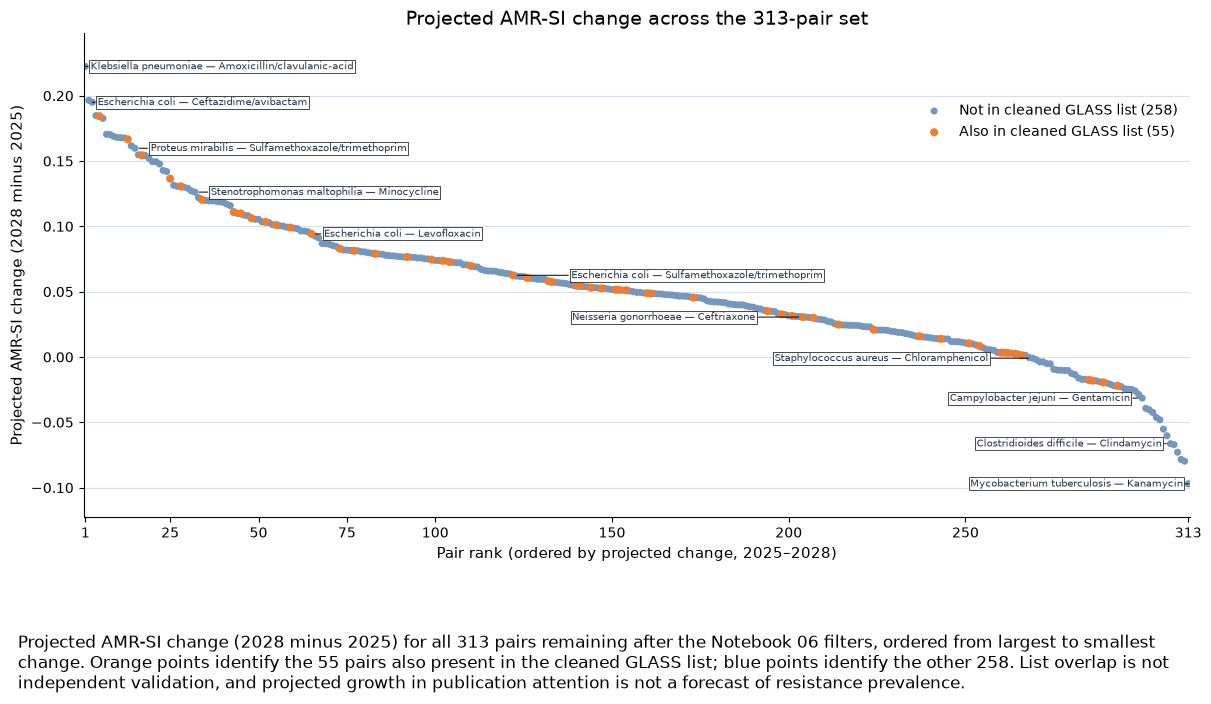

In [33]:
BLUE = "#7397bd"
ORANGE = "#ed7d31"

fig, ax = plt.subplots(figsize=(12, 5.6), constrained_layout=True)
not_glass = plot_df.loc[~plot_df["is_glass_pair"]]
in_glass = plot_df.loc[plot_df["is_glass_pair"]]

ax.scatter(
    not_glass["pair_rank"], not_glass["si_change"],
    s=26, color=BLUE, edgecolors="none",
    label=f"Not in cleaned GLASS list ({len(not_glass):,})", zorder=2,
)
ax.scatter(
    in_glass["pair_rank"], in_glass["si_change"],
    s=34, color=ORANGE, edgecolors="none",
    label=f"Also in cleaned GLASS list ({len(in_glass):,})", zorder=3,
)

# Add representative one-line labels just to the right of their points.
# Extend each horizontal leader only until the label clears the following dots.
N_REPRESENTATIVE_LABELS = 11
y_targets = np.linspace(
    float(plot_df["si_change"].max()),
    float(plot_df["si_change"].min()),
    min(N_REPRESENTATIVE_LABELS, len(plot_df)),
)
label_positions = np.unique(
    [int(np.abs(plot_df["si_change"].to_numpy() - target).argmin()) for target in y_targets]
)
representative_labels = [
    f"{plot_df.iloc[row_i]['pathogen']} — {plot_df.iloc[row_i]['antibiotic']}"
    for row_i in label_positions
]
y_span = float(plot_df["si_change"].max() - plot_df["si_change"].min())
label_clearance = max(0.002, y_span * 0.02)
label_start_xs = []
for row_i in label_positions:
    point_y = float(plot_df.iloc[row_i]["si_change"])
    later_y = plot_df.iloc[row_i + 1 :]["si_change"].to_numpy(dtype=float)
    clear_offsets = np.flatnonzero((point_y - later_y) >= label_clearance)
    # Keep the label tangent to its point when there are no nearby dots to clear.
    label_start_x = float(plot_df.iloc[row_i]["pair_rank"]) + 0.8
    if len(clear_offsets):
        first_clear_rank = float(plot_df.iloc[row_i + 1 + clear_offsets[0]]["pair_rank"])
        label_start_x = max(label_start_x, first_clear_rank + 0.5)
    label_start_xs.append(label_start_x)

# Use right-side labels for the first half and left-side labels for the rest.
for row_i, label in zip(label_positions, representative_labels):
    row = plot_df.iloc[row_i]
    point_x = float(row["pair_rank"])
    point_y = float(row["si_change"])
    if row_i < len(plot_df) / 2:
        later_y = plot_df.iloc[row_i + 1 :]["si_change"].to_numpy(dtype=float)
        clear_offsets = np.flatnonzero((point_y - later_y) >= label_clearance)
        label_start_x = point_x + 0.8
        if len(clear_offsets):
            first_clear_rank = float(plot_df.iloc[row_i + 1 + clear_offsets[0]]["pair_rank"])
            label_start_x = max(label_start_x, first_clear_rank + 0.5)
        text_alignment = "left"
    else:
        earlier_y = plot_df.iloc[:row_i]["si_change"].to_numpy(dtype=float)
        clear_offsets = np.flatnonzero((earlier_y - point_y) >= label_clearance)
        label_start_x = point_x - 0.8
        if len(clear_offsets):
            last_clear_rank = float(plot_df.iloc[clear_offsets[-1]]["pair_rank"])
            label_start_x = min(label_start_x, last_clear_rank - 0.5)
        text_alignment = "right"

    ax.annotate(
        label,
        xy=(point_x, point_y),
        xytext=(label_start_x, point_y),
        textcoords="data",
        ha=text_alignment,
        va="center",
        fontsize=7,
        color="#26364a",
        bbox=dict(facecolor="white", edgecolor="black", linewidth=0.5, alpha=1, pad=1),
        arrowprops=dict(arrowstyle="-", color="black", linewidth=0.7, shrinkA=1, shrinkB=3, zorder=1),
        zorder=4,
    )

ax.set_title(f"Projected AMR-SI change across the {len(plot_df):,}-pair set", fontsize=14)
ax.set_xlabel(f"Pair rank (ordered by projected change, {REFERENCE_YEAR}–{FUTURE_YEAR})", fontsize=11)
ax.set_ylabel(f"Projected AMR-SI change ({FUTURE_YEAR} minus {REFERENCE_YEAR})", fontsize=11)
ax.set_xlim(0.5, len(plot_df) + 0.5)
ax.margins(y=0.08)
ax.set_xticks(sorted(set([1, 25, 50, 75, 100, 150, 200, 250, len(plot_df)]).intersection(range(1, len(plot_df) + 1))))
ax.grid(axis="y", color="#d7e2f1", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.88), ncols=1)

caption = (
    f"Projected AMR-SI change ({FUTURE_YEAR} minus {REFERENCE_YEAR}) for all {len(plot_df):,} pairs "
    f"remaining after the Notebook 06 filters, ordered from largest to smallest change. "
    f"Orange points identify the {len(in_glass):,} pairs also present in the cleaned GLASS list; "
    f"blue points identify the other {len(not_glass):,}. List overlap is not independent validation, "
    "and projected growth in publication attention is not a forecast of resistance prevalence."
)
fig.text(0.01, -0.12, caption, ha="left", va="top", fontsize=12, wrap=True)

if SAVE_FIGURE:
    fig.savefig(FIGURE_STEM.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_STEM.with_suffix(".pdf"), bbox_inches="tight")
    print(f"Saved: {FIGURE_STEM.with_suffix('.png')}")
    print(f"Saved: {FIGURE_STEM.with_suffix('.pdf')}")
plt.show()